# Polblog

In [1]:
%load_ext autoreload
%autoreload 2

[0 1]
[]


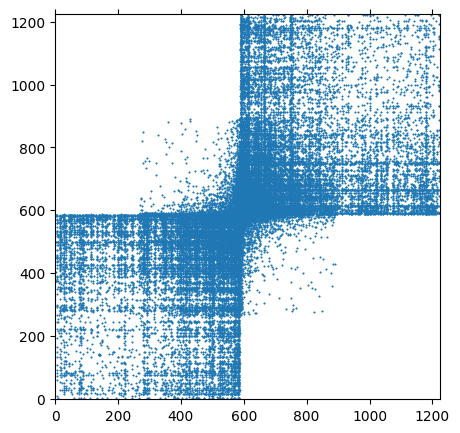

In [2]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from pygraphon.plots.plot_matrices import spy
# reload data to make sure no pollution from previous manipulations
G_gml = nx.read_gml("polblogs.gml", destringizer=int).to_undirected(reciprocal=False, as_view=False)

G_gml.remove_nodes_from(list(nx.isolates(G_gml)))

# Compute the number of connection to the opposite party
def count_cross_connections(graph,node) -> int:
    neighbors = graph.neighbors(node[0])
    count = 0
    for neighbor in neighbors:
        if node[1] != graph.nodes[neighbor]["value"]:
            count += 1
    return count

inter_connections ={node[0]: count_cross_connections(G_gml,node) for node in G_gml.nodes(data="value")}

# Sort nodes by increasing degrees within each membership group
nodes_0 = [node[0] for node in G_gml.nodes(data="value") if node[1] == 0 ]
nodes_1 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 1]

nodes_0_sorted = sorted(nodes_0, key=lambda node: inter_connections[node], reverse=False)
nodes_1_sorted = sorted(nodes_1, key=lambda node: inter_connections[node], reverse=True)

# Create the reordered adjacency matrix
reordered_A_gml = nx.adjacency_matrix(G_gml, nodelist=nodes_0_sorted  + nodes_1_sorted).toarray()
reordered_A_gml -= np.diag(np.diag(reordered_A_gml))
reordered_A_gml[reordered_A_gml == 2] = 1
print(np.unique(reordered_A_gml))
print(np.argwhere(reordered_A_gml == 2))
spy(reordered_A_gml, marker_size=0.5, origin="lower")
plt.show()

In [3]:
from pygraphon import HistogramEstimator, SmoothNetHist

est = SmoothNetHist()
est.fit(reordered_A_gml)
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= reordered_A_gml)
est_origin = HistogramEstimator()
est_origin.fit(reordered_A_gml)

print(est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(est_origin.get_graphon().graphon)))

0.1895424836601307
Number of unique parameters in SmoothNetHist: 29
Number of unique parameters in Olhede: 83


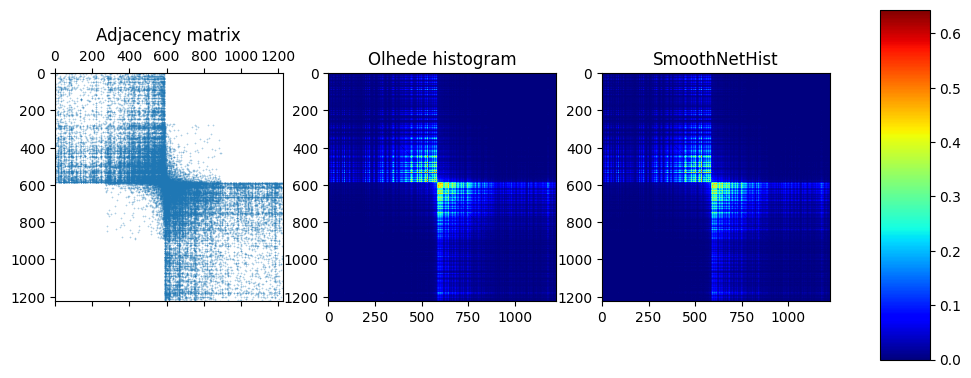

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(est_origin.get_edge_connectivity(), cmap='jet')#, vmin=0, vmax=1)
im2 = ax[2].imshow(est.get_edge_connectivity(), cmap='jet')#, vmin=0, vmax=1)
_ = spy(reordered_A_gml, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("Olhede histogram")
ax[2].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)

plt.show()

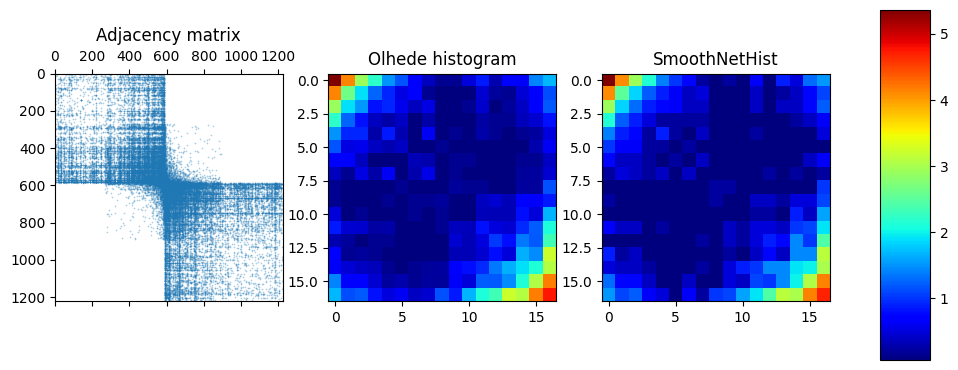

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(np.sqrt(est_origin.get_graphon().graphon), cmap='jet')#, vmin=0, vmax=1)
im2 = ax[2].imshow(np.sqrt(est.get_graphon().graphon), cmap='jet')#, vmin=0, vmax=1)
_ = spy(reordered_A_gml, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("Olhede histogram")
ax[2].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)

plt.show()

## Selecting at which point I should cut the graphon

In [7]:
def print_array_with_indices(arr):
    for index, value in np.ndenumerate(arr):
        print(f"Index: {index}, Value: {value}")

print_array_with_indices(np.diag(est_origin.graphon.get_graphon()))

Index: (0,), Value: 28.399114802128718
Index: (1,), Value: 6.679145492062589
Index: (2,), Value: 2.1244101437858105
Index: (3,), Value: 0.08497640575143242
Index: (4,), Value: 0.6288254025605999
Index: (5,), Value: 0.10197168690171891
Index: (6,), Value: 0.06798112460114594
Index: (7,), Value: 0.23793393610401078
Index: (8,), Value: 0.0
Index: (9,), Value: 0.0
Index: (10,), Value: 0.0
Index: (11,), Value: 0.5778395591097405
Index: (12,), Value: 0.9517357444160431
Index: (13,), Value: 0.18694809265315135
Index: (14,), Value: 3.382060948907011
Index: (15,), Value: 8.990503728501551
Index: (16,), Value: 22.244792420704457


In [8]:
turn_index = 8
end_index = est_origin.graphon.get_graphon().shape[0]
sort_index_dem = [turn_index - (i+1) for i in range(turn_index) ] + [end_index - (i+1) for i in range(end_index - turn_index)]
print(sort_index_dem)

[7, 6, 5, 4, 3, 2, 1, 0, 16, 15, 14, 13, 12, 11, 10, 9, 8]


## Permuting according to index

In [9]:
graphon_polblogs = est.graphon.get_graphon()
# Get the diagonal elements
diagonal = np.diag(graphon_polblogs)

# Sort the diagonal elements in increasing order and get the sorting indices
sorting_indices = np.argsort(diagonal)
print(sorting_indices)

# Permute the rows and columns of the matrix based on the sorting indices
graphon_polblogs_permuted = graphon_polblogs[sort_index_dem][:, sort_index_dem]

print(graphon_polblogs_permuted.shape)

[ 5  6  7  9 10  8 13  3 11  4 12  2 14  1 15 16  0]
(17, 17)


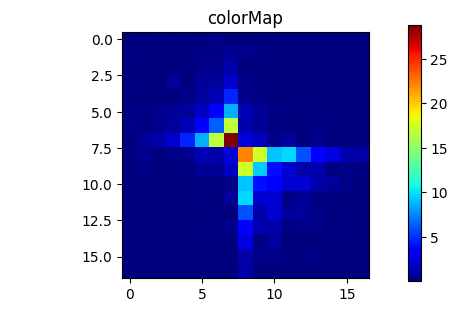

In [10]:
fig = plt.figure(figsize=(6, 3.2))

ax = fig.add_subplot(111)
ax.set_title('colorMap')
plt.imshow(graphon_polblogs_permuted, cmap='jet')
ax.set_aspect('equal')

cax = fig.add_axes([0.12, 0.1, 0.78, 0.8])
cax.get_xaxis().set_visible(False)
cax.get_yaxis().set_visible(False)
cax.patch.set_alpha(0)
cax.set_frame_on(False)
plt.colorbar(orientation='vertical', ax = cax)
plt.show()

## 3d plots

In [17]:
import numpy as np
from ... import plot_3d_and_reflection

# Plot the 3D plot and its reflection
plot_3d_and_reflection(np.sqrt(graphon_polblogs_permuted))


ImportError: attempted relative import with no known parent package

In [ ]:
from mpl3d.camera import Camera
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from new_plots import Bar

Z = np.sqrt(graphon_polblogs_permuted).copy()*est.graphon.initial_rho

cmap = plt.get_cmap("jet")
norm = mpl.colors.Normalize(vmin=Z.min(),vmax=Z.max())
facecolors = cmap(norm(Z))


fig = plt.figure(figsize=(8,8), dpi=600)
ax = fig.add_axes([0,0,1,1], xlim=[-1,+1], ylim=[-1,0], aspect=1)
ax.axis("off")

camera = Camera("perspective", 70, -135+90, scale=1)
bars = Bar(ax, camera.transform, Z, facecolors=facecolors)
camera.connect(ax, bars.update)

plt.show()